### Assignment 3 — Sampling Distributions and Estimation ###

Participants:
- Dimitar Asenov Nizamov - 34468
- Marius Marcoci - 345963
- Plamen Plamenov Michev - 343810

## Table of contents

- [Setup — imports and data](#setup)
- [Part 1 — Sampling distributions and the CLT](#part1)
    - [a) Simulate sample means and summary table](#p1a)
    - [b) Sampling distributions with normal overlay](#p1b)
    - [c) $P(\bar X > 75)$: simulation vs. CLT](#p1c)
    - [d) Smallest $n$ with $\operatorname{SE}(\bar X) \le 6$](#p1d)
    - [e) Running mean and the law of large numbers](#p1e)
    - [f) What the CLT does and does not do](#p1f)
- [Part 2 — Estimating mean sensor error](#part2)
    - [a) $n$, $\bar x$, $s$ and standard error](#p2a)
    - [b) Histogram and normal QQ-plot](#p2b)
    - [c) 95% $t$ interval step by step](#p2c)
    - [d) 90%, 95% and 99% $t$ intervals](#p2d)
    - [e) Sample-size planning](#p2e)
    - [f) Percentile bootstrap interval](#p2f)
- [Part 3 — Estimating a false-rejection proportion](#part3)
    - [a) $n$, $x$ and $\hat p$](#p3a)
    - [b) 95% Wilson interval](#p3b)
    - [c) 95% Wald interval vs. Wilson](#p3c)
    - [d) 90%, 95% and 99% Wilson intervals](#p3d)
    - [e) Sample-size planning](#p3e)
- [Part 4 — AI-use and conclusion](#part4)
    - [AI-use](#ai)
    - [Overall conclusion](#conclusion)

<a id="setup"></a>
## Setup — imports and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm, expon, t, bootstrap
from statsmodels.stats.proportion import proportion_confint

sensors = pd.read_csv("data/assignment03_sensor_calibration.csv")
access = pd.read_csv("data/assignment03_access_control.csv")

display(sensors.head())
display(access.head())

,sensor_id,calibration_error_c
0,1,0.334
1,2,0.383
2,3,1.644
3,4,0.627
4,5,0.615


,attempt_id,false_reject
0,1,0
1,2,0
2,3,0
3,4,1
4,5,0


<a id="part1"></a>
## Part 1 — Sampling distributions and the CLT

Restoration time in a service system is modelled as exponential with population mean and standard deviation $\mu=\sigma=60$ minutes. Use this known population model and NumPy's random generator with seed 2026 and at least 20,000 repetitions per sample size.

<a id="p1a"></a>
#### a) Simulate samples for $n=1,5,20,80$ and store their means. Create a table with $n$, theoretical mean, simulated mean of means, theoretical standard error $\sigma/\sqrt n$, and empirical standard deviation of the simulated means.

In [2]:
mu = sigma = 60.0                
n_rep = 20_000                   
sample_sizes = [1, 5, 20, 80]
rng = np.random.default_rng(2026)

means = {}
for n in sample_sizes:
    samples = rng.exponential(scale=mu, size=(n_rep, n))  
    means[n] = samples.mean(axis=1)                       

rows = []
for n in sample_sizes:
    rows.append({
        "n": n,
        "theoretical mean": mu,
        "simulated mean of means": means[n].mean(),
        "theoretical SE": sigma / np.sqrt(n),
        "empirical SD of means": means[n].std(ddof=1),
    })

table_1a = pd.DataFrame(rows)
table_1a.round(3)

,n,theoretical mean,simulated mean of means,theoretical SE,empirical SD of means
0,1,60.0,60.328,60.000,60.199
1,5,60.0,59.500,26.833,26.684
2,20,60.0,59.937,13.416,13.353
3,80,60.0,59.990,6.708,6.740


<a id="p1b"></a>
#### b) Create one figure showing the four sampling distributions with density histograms and overlay $N(\mu,\sigma^2/n)$. Explain how centre, spread, and shape change and why the normal curve is an approximation for this non-normal population.

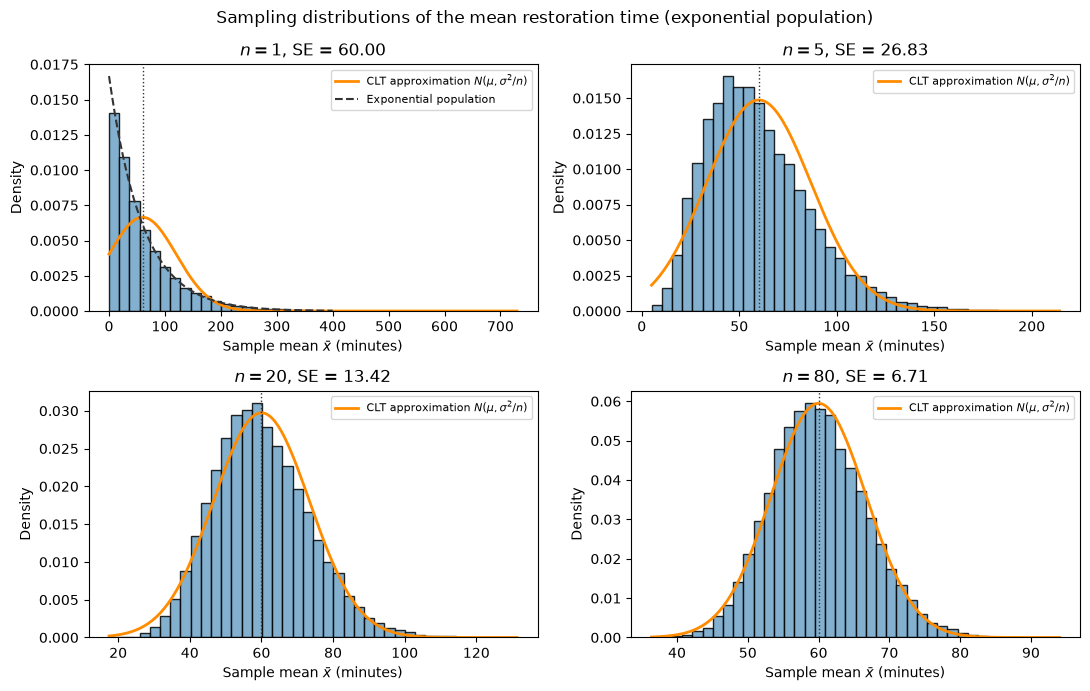

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
xs_pop = np.linspace(0, 400, 400)
for ax, n in zip(axes.flat, sample_sizes):
    se = sigma / np.sqrt(n)
    ax.hist(means[n], bins=40, density=True, color="#6CA2C6", edgecolor="black", alpha=0.85)
    x_grid = np.linspace(means[n].min(), means[n].max(), 200)
    ax.plot(x_grid, norm.pdf(x_grid, loc=mu, scale=se), color="#FF8C00", lw=2,
            label=r"CLT approximation $N(\mu, \sigma^2/n)$")
    if n == 1:
        ax.plot(xs_pop, expon.pdf(xs_pop, scale=mu), color="0.2", lw=1.5, linestyle="--",
                label="Exponential population")
    ax.axvline(mu, color="0.2", lw=1, linestyle=":")
    ax.set_xlabel(r"Sample mean $\bar{x}$ (minutes)")
    ax.set_ylabel("Density")
    ax.set_title(rf"$n={n}$, SE = {se:.2f}")
    ax.legend(fontsize=8)
fig.suptitle("Sampling distributions of the mean restoration time (exponential population)")
plt.tight_layout()
plt.show()

- **Centre:** all four histograms are centred near $\mu = 60$ minutes (dotted line), in line with $E[\bar X] = \mu$.
- **Spread:** the histograms become narrower as $n$ grows. The spread follows $\operatorname{SE}(\bar X) = \sigma/\sqrt n$: 60, 26.83, 13.42 and 6.71 minutes.
- **Shape:** for $n=1$ the "mean" is a single observation, so the histogram is the exponential population itself: strongly right-skewed with its peak at 0. The normal curve describes it badly and even puts density on negative restoration times. For $n=5$ the means are still clearly right-skewed, with the peak left of 60 and a long right tail. For $n=20$ the shape is nearly bell-shaped with a slight right skew left, and for $n=80$ it is close to the normal curve.

**Why the normal curve is only an approximation:** only when the population itself is normal is $\bar X \sim N(\mu, \sigma^2/n)$ *exact* for every $n$. Restoration times are exponential, not normal, so for any finite $n$ the sampling distribution of $\bar X$ keeps some of the population's right skew. The central limit theorem only says that $\bar X \approx N(\mu, \sigma^2/n)$, an approximation that improves as $n$ grows. How large $n$ must be depends on how skewed the population is; there is no universal threshold such as $n = 30$.

<a id="p1c"></a>
#### c) For $n=20$ and $n=80$, estimate $P(\bar X>75)$ by simulation and calculate the CLT approximation. Compare the values.

In [4]:
threshold = 75
rows = []
for n in (20, 80):
    se = sigma / np.sqrt(n)
    rows.append({
        "n": n,
        "SE": se,
        "z = (75 - mu) / SE": (threshold - mu) / se,
        "simulated P(mean > 75)": np.mean(means[n] > threshold),  
        "CLT approximation": norm.sf(threshold, loc=mu, scale=se),
    })

table_1c = pd.DataFrame(rows)
table_1c.round(4)

,n,SE,z = (75 - mu) / SE,simulated P(mean > 75),CLT approximation
0,20,13.4164,1.1180,0.1334,0.1318
1,80,6.7082,2.2361,0.0186,0.0127


- **$n = 20$:** the simulated proportion (0.1334) and the CLT approximation (0.1318) are very close.
- **$n = 80$:** the simulated proportion is 0.0186 while the CLT approximation is 0.0127. The absolute difference is small, but the normal approximation underestimates this tail probability by roughly a third.

The difference is not simulation noise. With 20,000 repetitions, the simulated proportion is accurate to about $\pm 0.001$. The reason is the remaining right skew: the sampling distribution of $\bar X$ still has a longer right tail than the symmetric normal curve. A value of 75 lies 2.24 standard errors above $\mu$ for $n = 80$. That is far out in the tail, where the approximation is weakest. The simulated value is the better description of this exponential model; the CLT value is a shortcut.

The probability also drops sharply from $n=20$ to $n=80$: because the standard error shrinks, a sample mean 15 minutes above $\mu$ becomes much less likely.

<a id="p1d"></a>
#### d) Find the smallest integer $n$ for which $\operatorname{SE}(\bar X)\le6$ minutes and verify it by simulation.

In [5]:
n_required = int(np.ceil((sigma / 6) ** 2))
print("Smallest sample size:", n_required)

for n in (n_required - 1, n_required):
    print(f"n = {n}: theoretical SE = {sigma / np.sqrt(n):.4f} minutes")

print()
for n in (n_required - 1, n_required):
    sim_means = rng.exponential(scale=mu, size=(n_rep, n)).mean(axis=1)
    print(f"n = {n}: simulated SD of means = {sim_means.std(ddof=1):.4f} minutes")

Smallest sample size: 100
n = 99: theoretical SE = 6.0302 minutes
n = 100: theoretical SE = 6.0000 minutes

n = 99: simulated SD of means = 6.0799 minutes
n = 100: simulated SD of means = 6.0194 minutes


<a id="p1e"></a>
#### e) Generate one sequence of 5,000 observations and plot its running mean. Explain the law of large numbers and how this plot differs from a sampling distribution.

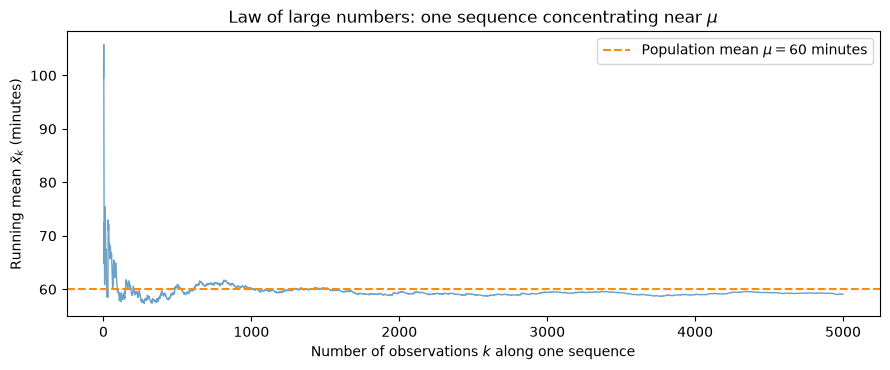

Running mean after 10, 100, 1000, 5000 observations: 67.88, 59.94, 60.13, 59.07


In [6]:
n_lln = 5_000
one_sequence = rng.exponential(scale=mu, size=n_lln)                 
running_mean = np.cumsum(one_sequence) / np.arange(1, n_lln + 1)   

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(np.arange(1, n_lln + 1), running_mean, color="#6CA2C6", lw=1)
ax.axhline(mu, color="#FF8C00", linestyle="--", label=r"Population mean $\mu = 60$ minutes")
ax.set_xlabel("Number of observations $k$ along one sequence")
ax.set_ylabel(r"Running mean $\bar{x}_k$ (minutes)")
ax.set_title(r"Law of large numbers: one sequence concentrating near $\mu$")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Running mean after 10, 100, 1000, 5000 observations: "
      f"{running_mean[9]:.2f}, {running_mean[99]:.2f}, {running_mean[999]:.2f}, {running_mean[-1]:.2f}")

**Law of large numbers:** as more and more observations are added to *one* sequence, the running mean $\bar x_k$ settles close to the population mean $\mu$. In the plot, the running mean jumps around strongly at first (67.88 after 10 observations), then stays close to 60 (59.94 after 100, 60.13 after 1,000 and 59.07 after 5,000 observations). It does not approach 60 monotonically: the deviations become smaller in typical size, but they do not disappear. The remaining deviation after 5,000 observations (about 0.9 minutes) is about one standard error ($60/\sqrt{5000} \approx 0.85$).

**How it differs from a sampling distribution:**

| Running mean (LLN) | Sampling distribution |
|---|---|
| *One* sequence whose length $k$ grows | *Many* independent samples, each of a *fixed* size $n$ |
| Each point reuses the previous observations, so neighbouring points share almost all their data | Every sample mean comes from new, independent data |
| Shows that $\bar x_k$ gets close to $\mu$ | Shows the centre, spread and shape of $\bar X$ across repeated samples |

The LLN is about *concentration near* $\mu$. The CLT is about the *approximate normal shape* of the sampling distribution.

<a id="p1f"></a>
#### f) State explicitly that the CLT concerns sample means. It neither makes individual restoration times normal nor repairs dependence, drift, or unrepresentative sampling.

**The central limit theorem concerns sample means, not individual observations.** It states that, for i.i.d. observations with finite variance, the sampling distribution of $\bar X$ is approximately $N(\mu, \sigma^2/n)$ when $n$ is large enough.

- It does **not** make individual restoration times normal. A single restoration time is still exponential and right-skewed no matter how large $n$ is. For a probability about one restoration time, the exponential model must be used, not the normal approximation.
- It does **not** repair dependence. If restoration times are correlated, for example because several repairs are caused by the same outage, the observations are not independent and $\sigma/\sqrt n$ understates the true standard error.
- It does **not** repair drift. If the mean restoration time changes over time (new staff, seasonal load), there is no single $\mu$ to which the sample mean converges.
- It does **not** repair unrepresentative sampling. If only the easy repairs are recorded, $\bar X$ is centred on the wrong value, and a larger $n$ only makes the wrong answer more precise.

<a id="part2"></a>
## Part 2 — Estimating mean sensor error

The file `assignment03_sensor_calibration.csv` contains calibration errors from 64 independently selected temperature sensors. Error is `sensor reading − reference temperature`. Let $\mu$ be the population mean calibration error.

<a id="p2a"></a>
#### a) Report $n$, $\bar x$, $s$, and the estimated standard error. Explain standard deviation versus standard error.

In [8]:
x = sensors["calibration_error_c"].to_numpy()
n = x.size
xbar = x.mean()
s = x.std(ddof=1)
se = s / np.sqrt(n)

print(f"n = {n}")
print(f"sample mean = {xbar:.4f} °C")
print(f"sample SD s = {s:.4f} °C")
print(f"SE = s/sqrt(n) = {se:.4f} °C")

n = 64
sample mean = 0.1883 °C
sample SD s = 0.6257 °C
SE = s/sqrt(n) = 0.0782 °C


**Standard deviation vs. standard error:**
- The **standard deviation** $s = 0.63$ °C describes how much *individual sensors* differ from each other: a typical sensor's error lies about 0.63 °C away from the average error.
- The **standard error** $s/\sqrt n = 0.078$ °C describes how precisely the *sample mean* estimates the population mean $\mu$: if the study were repeated with 64 other sensors, the new sample mean would typically differ from this one by about 0.08 °C.

<a id="p2b"></a>
#### b) Create a histogram and normal QQ-plot. Discuss whether a one-sample $t$ interval appears reasonable and why plots cannot establish independence.

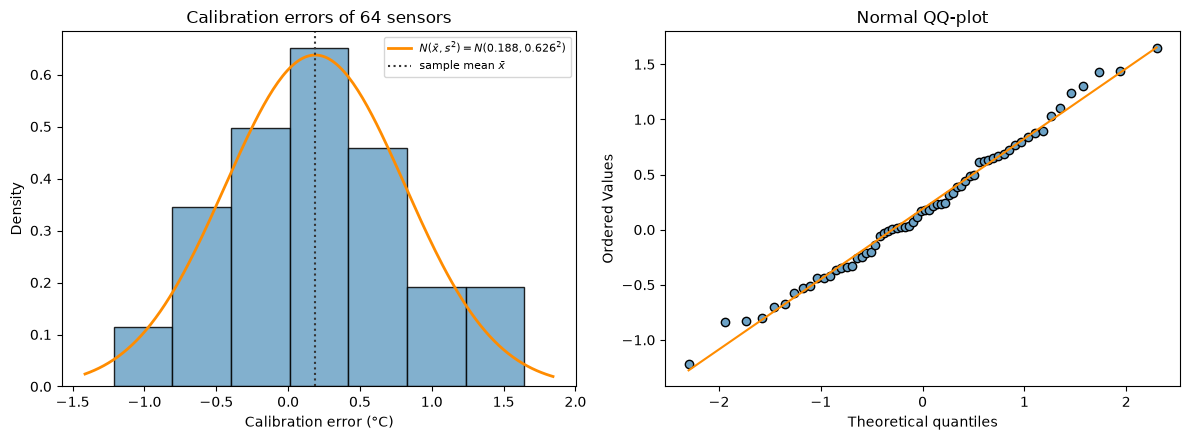

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.hist(x, bins="auto", density=True, color="#6CA2C6", edgecolor="black", alpha=0.85)
x_grid = np.linspace(x.min() - 0.2, x.max() + 0.2, 200)
ax1.plot(x_grid, norm.pdf(x_grid, loc=xbar, scale=s), color="#FF8C00", lw=2,
         label=rf"$N(\bar x, s^2) = N({xbar:.3f}, {s:.3f}^2)$")
ax1.axvline(xbar, color="0.2", linestyle=":", label=r"sample mean $\bar x$")
ax1.set_title("Calibration errors of 64 sensors")
ax1.set_xlabel("Calibration error (°C)")
ax1.set_ylabel("Density")
ax1.legend(fontsize=8)

stats.probplot(x, dist="norm", plot=ax2)
ax2.set_title("Normal QQ-plot")
ax2.get_lines()[0].set_markerfacecolor("#6CA2C6")
ax2.get_lines()[0].set_markeredgecolor("black")
ax2.get_lines()[1].set_color("#FF8C00")

plt.tight_layout()
plt.show()

- **Histogram:** the calibration errors are roughly symmetric and single-peaked around the sample mean, with no extreme outliers, and the fitted normal curve follows the bars reasonably well.
- **QQ-plot:** the points lie close to the straight line. The few highest values sit slightly above the line (a slightly longer right tail), but there is no systematic curve.

**Is a one-sample $t$ interval reasonable?** The $t$ interval is exact when the population is normal, and these data show no clear departure from normality. With $n = 64$, the sampling distribution of $\bar X$ would also be close to normal by the central limit theorem, even if the population were mildly non-normal.

**Why the plots cannot establish independence:** a histogram and a QQ-plot only show *which values* occurred, not *how they were collected*. For example, sensors from the same production batch or calibrated against the same reference might share part of their error. Such dependent data could produce exactly the same histogram and QQ-plot. Independence has to be justified from the study design; here the sensors are stated to be *independently selected*. If they were dependent, $s/\sqrt n$ would understate the true uncertainty of $\bar x$.

<a id="p2c"></a>
#### c) Construct a 95% $t$ interval by calculating the degrees of freedom, critical value, standard error, and margin of error. Verify it with SciPy and interpret both the interval and the 95% confidence level correctly.

In [10]:
df_t = n - 1
t_crit = t.ppf(0.975, df_t)
moe = t_crit * se
ci_lo, ci_hi = xbar - moe, xbar + moe

print(f"degrees of freedom = n - 1 = {df_t}")
print(f"critical value t(63, 0.975) = {t_crit:.4f}")
print(f"standard error = {se:.4f} °C")
print(f"margin of error = {t_crit:.4f} x {se:.4f} = {moe:.4f} °C")
print(f"95% t interval = [{ci_lo:.4f}, {ci_hi:.4f}] °C")

ci_scipy = t.interval(0.95, df_t, loc=xbar, scale=se)
print(f"SciPy check = [{ci_scipy[0]:.4f}, {ci_scipy[1]:.4f}] °C")

degrees of freedom = n - 1 = 63
critical value t(63, 0.975) = 1.9983
standard error = 0.0782 °C
margin of error = 1.9983 x 0.0782 = 0.1563 °C
95% t interval = [0.0320, 0.3446] °C
SciPy check = [0.0320, 0.3446] °C


**Interpretation of the interval:** we estimate that the population mean calibration error $\mu$ of sensors of this type lies between 0.032 and 0.345 °C. The whole interval lies above 0, so the data indicate that these sensors read slightly too high on average. The interval is about the *mean* error, not about individual sensors: individual errors in the sample range from about −1.2 to +1.6 °C.

**Interpretation of the 95% confidence level:** the 95% describes the *procedure*, not this particular interval. If the study were repeated many times, each time with 64 new independently selected sensors and a new interval, about 95% of those intervals would contain the true $\mu$. For this one interval, $\mu$ is fixed: it either lies inside [0.032, 0.345] or it does not. It is therefore *not* correct to say that "$\mu$ lies in this interval with probability 0.95".

<a id="p2d"></a>
#### d) Create a table of 90%, 95%, and 99% $t$ intervals and widths. Explain the confidence–precision trade-off.

In [11]:
rows = []
for level in (0.90, 0.95, 0.99):
    q = t.ppf((1 + level) / 2, df_t)
    rows.append({
        "confidence level": f"{level:.0%}",
        "t critical value": q,
        "margin of error": q * se,
        "lower": xbar - q * se,
        "upper": xbar + q * se,
        "width": 2 * q * se,
    })

table_2d = pd.DataFrame(rows)
table_2d.round(4)

,confidence level,t critical value,margin of error,lower,upper,width
0,90%,1.6694,0.1306,0.0577,0.3188,0.2612
1,95%,1.9983,0.1563,0.0320,0.3446,0.3126
2,99%,2.6561,0.2078,-0.0195,0.3960,0.4155


**Confidence–precision trade-off:** a higher confidence level requires a larger critical value, so the interval becomes wider. The 99% interval is about 59% wider than the 90% interval. More confidence that the procedure captures $\mu$ is paid for with a less precise (wider) interval. For a fixed sample, both cannot be improved at the same time. Only more data (a larger $n$, hence a smaller standard error) narrows the interval without lowering the confidence level.

The 99% interval is the only one that contains 0: at that confidence level, a mean error of zero remains a plausible value, while the 90% and 95% intervals lie entirely above 0.

<a id="p2e"></a>
#### e) Using $s$ as a planning value and the normal critical value, find the smallest approximate sample size for a 95% margin of error no larger than $0.10\ ^\circ\mathrm C$.

In [12]:
target_moe = 0.10
z_crit = norm.ppf(0.975)
n_exact = (z_crit * s / target_moe) ** 2
n_plan = int(np.ceil(n_exact))

print(f"planning SD s = {s:.4f} °C, z(0.975) = {z_crit:.4f}")
print(f"n >= (z * s / E)^2 = ({z_crit:.4f} x {s:.4f} / {target_moe})^2 = {n_exact:.2f}")
print(f"smallest sample size: {n_plan}")
print()
for m in (n_plan - 1, n_plan):
    print(f"n = {m}: margin of error = {z_crit * s / np.sqrt(m):.4f} °C")

planning SD s = 0.6257 °C, z(0.975) = 1.9600
n >= (z * s / E)^2 = (1.9600 x 0.6257 / 0.1)^2 = 150.42
smallest sample size: 151

n = 150: margin of error = 0.1001 °C
n = 151: margin of error = 0.0998 °C


<a id="p2f"></a>
#### f) With seed 2026 and at least 10,000 resamples, construct a percentile bootstrap interval. Compare it with the $t$ interval and state what the comparison cannot validate.

,interval,lower,upper,width
0,95% t interval,0.0320,0.3446,0.3126
1,95% percentile bootstrap,0.0408,0.3413,0.3005


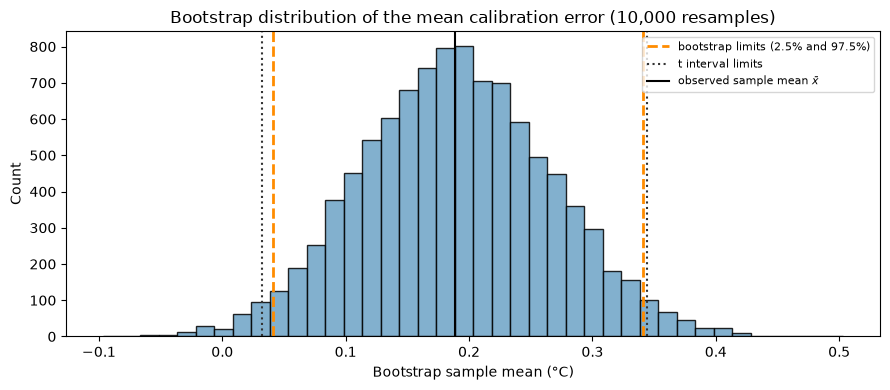

In [13]:
boot = bootstrap(
    (x,),
    np.mean,
    confidence_level=0.95,
    n_resamples=10_000,
    method="percentile",
    rng=np.random.default_rng(2026),
)
boot_lo, boot_hi = boot.confidence_interval.low, boot.confidence_interval.high

comparison = pd.DataFrame({
    "interval": ["95% t interval", "95% percentile bootstrap"],
    "lower": [ci_lo, boot_lo],
    "upper": [ci_hi, boot_hi],
    "width": [ci_hi - ci_lo, boot_hi - boot_lo],
})
display(comparison.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(boot.bootstrap_distribution, bins=40, color="#6CA2C6", edgecolor="black", alpha=0.85)
ax.axvline(boot_lo, color="#FF8C00", lw=2, linestyle="--", label="bootstrap limits (2.5% and 97.5%)")
ax.axvline(boot_hi, color="#FF8C00", lw=2, linestyle="--")
ax.axvline(ci_lo, color="0.2", lw=1.5, linestyle=":", label="t interval limits")
ax.axvline(ci_hi, color="0.2", lw=1.5, linestyle=":")
ax.axvline(xbar, color="black", lw=1.5, label=r"observed sample mean $\bar x$")
ax.set_xlabel("Bootstrap sample mean (°C)")
ax.set_ylabel("Count")
ax.set_title("Bootstrap distribution of the mean calibration error (10,000 resamples)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**How the bootstrap works:** we draw 64 values *with replacement* from the 64 observed errors and compute their mean, and repeat this 10,000 times. The histogram of these 10,000 bootstrap means imitates the sampling distribution of $\bar X$. The percentile interval is the middle 95% of those means, i.e. the 2.5% and 97.5% percentiles.

| interval | lower | upper | width |
|---|---|---|---|
| 95% $t$ interval | 0.0320 | 0.3446 | 0.313 |
| 95% percentile bootstrap | 0.0408 | 0.3413 | 0.300 |

The two intervals are very similar. The bootstrap distribution is bell-shaped and nearly symmetric around $\bar x$, which supports the normal approximation behind the $t$ interval. The bootstrap interval is slightly narrower, partly because it does not include the $t$ distribution's extra allowance for estimating $\sigma$.

**What the comparison cannot validate:** both intervals are computed from *the same 64 observations*. The bootstrap only reuses the sample; it creates no new information. If the sensors are not representative of the population, if they are not independent, or if the reference temperature itself is biased, both intervals are wrong in the same way and will still agree with each other. The agreement therefore does not show that the sample is representative or independent, that the interval really has 95% coverage, or that $\mu$ is actually inside it.

<a id="part3"></a>
## Part 3 — Estimating a false-rejection proportion

The file `assignment03_access_control.csv` contains 240 independently staged legitimate login attempts. `false_reject` equals 1 when a legitimate attempt was rejected and 0 otherwise. Let $p$ be the population false-rejection probability under the test conditions.

<a id="p3a"></a>
#### a) Report $n$, the number of false rejections $x$, and $\hat p$. Explain why $\hat p$ is also the sample mean of a binary variable.

In [15]:
y = access["false_reject"].to_numpy()
n_att = y.size
x_rej = int(y.sum())
p_hat = x_rej / n_att

print(f"n (attempts) = {n_att}")
print(f"x (false rejections) = {x_rej}")
print(f"p_hat = x / n = {x_rej}/{n_att} = {p_hat:.4f}")
print(f"mean of the 0/1 column = {y.mean():.4f}")

n (attempts) = 240
x (false rejections) = 20
p_hat = x / n = 20/240 = 0.0833
mean of the 0/1 column = 0.0833


<a id="p3b"></a>
#### b) Construct and interpret a 95% Wilson interval for $p$ with statsmodels. State the population and parameter clearly.

In [16]:
wilson = proportion_confint(x_rej, n_att, alpha=0.05, method="wilson")
print(f"95% Wilson interval for p = [{wilson[0]:.4f}, {wilson[1]:.4f}]")
print(f" = [{wilson[0]:.2%}, {wilson[1]:.2%}]")

95% Wilson interval for p = [0.0546, 0.1252]
 = [5.46%, 12.52%]


- **Population:** all legitimate login attempts made under the same test conditions (same system, configuration and type of user).
- **Parameter:** $p$, the probability that a legitimate login attempt is falsely rejected under these conditions.

<a id="p3c"></a>
#### c) Calculate the 95% Wald interval from its formula. Compare it with Wilson and explain why Wilson is the preferred default.

In [17]:
z = norm.ppf(0.975)
wald_se = np.sqrt(p_hat * (1 - p_hat) / n_att)
wald_moe = z * wald_se
wald = (p_hat - wald_moe, p_hat + wald_moe)

print(f"SE = sqrt(p_hat(1 - p_hat)/n) = sqrt({p_hat:.4f} x {1 - p_hat:.4f} / {n_att}) = {wald_se:.4f}")
print(f"margin of error = {z:.4f} x {wald_se:.4f} = {wald_moe:.4f}")
print(f"expected counts: n*p_hat = {n_att * p_hat:.0f}, n*(1 - p_hat) = {n_att * (1 - p_hat):.0f}")

comparison_p = pd.DataFrame({
    "interval": ["95% Wald", "95% Wilson"],
    "lower": [wald[0], wilson[0]],
    "upper": [wald[1], wilson[1]],
    "centre": [(wald[0] + wald[1]) / 2, (wilson[0] + wilson[1]) / 2],
    "width": [wald[1] - wald[0], wilson[1] - wilson[0]],
})
comparison_p.round(4)

SE = sqrt(p_hat(1 - p_hat)/n) = sqrt(0.0833 x 0.9167 / 240) = 0.0178
margin of error = 1.9600 x 0.0178 = 0.0350
expected counts: n*p_hat = 20, n*(1 - p_hat) = 220


,interval,lower,upper,centre,width
0,95% Wald,0.0484,0.1183,0.0833,0.0699
1,95% Wilson,0.0546,0.1252,0.0899,0.0706


**Comparison:**
- The two intervals have almost the same width (0.070 vs. 0.071).
- The Wald interval is symmetric around $\hat p = 0.0833$. The Wilson interval is shifted upwards (centre 0.0899, slightly towards 0.5) and reaches further on the upper side.
- Here the counts are reasonably large ($n\hat p = 20$ and $n(1-\hat p) = 220$, both at least 10), so the two intervals do not differ much.

**Why Wilson is the preferred default:** the Wald interval plugs $\hat p$ into the standard error and assumes $\hat p$ is exactly normal around it. This works poorly when $n$ is small or $p$ is close to 0 or 1. The Wald interval can then understate the uncertainty: it can produce a lower limit below 0, and if no failures are observed ($x = 0$) its standard error is 0, giving the meaningless interval [0, 0]. The Wilson interval always stays inside [0, 1], still gives a sensible interval when $x = 0$, and its actual coverage is closer to the stated confidence level.

<a id="p3d"></a>
#### d) Create a table of 90%, 95%, and 99% Wilson intervals and widths.

In [18]:
rows = []
for level in (0.90, 0.95, 0.99):
    lo, hi = proportion_confint(x_rej, n_att, alpha=1 - level, method="wilson")
    rows.append({
        "confidence level": f"{level:.0%}",
        "lower": lo,
        "upper": hi,
        "width": hi - lo,
    })

table_3d = pd.DataFrame(rows)
table_3d.round(4)

,confidence level,lower,upper,width
0,90%,0.0584,0.1175,0.0591
1,95%,0.0546,0.1252,0.0706
2,99%,0.0478,0.1412,0.0934


<a id="p3e"></a>
#### e) Estimate the sample size for a 95% margin of error no larger than 0.02 using first $p=0.5$ and then the observed $\hat p$. Round up and explain the difference.

In [19]:
target_moe_p = 0.02
z = norm.ppf(0.975)

rows = []
for label, p_plan in (("conservative p = 0.5", 0.5), (f"observed p_hat = {p_hat:.4f}", p_hat)):
    n_exact_p = z**2 * p_plan * (1 - p_plan) / target_moe_p**2
    rows.append({
        "planning value": label,
        "p(1 - p)": p_plan * (1 - p_plan),
        "n (exact)": n_exact_p,
        "n (rounded up)": int(np.ceil(n_exact_p)),
    })

table_3e = pd.DataFrame(rows)
table_3e.round(4)

,planning value,p(1 - p),n (exact),n (rounded up)
0,conservative p = 0.5,0.2500,2400.9118,2401
1,observed p_hat = 0.0833,0.0764,733.6119,734


**Why the two differ:** $p(1-p)$ is largest at $p = 0.5$, so $p = 0.5$ is the *worst case*. It guarantees the target margin whatever the true $p$ is, but it requires about 3.3 times as many attempts. Using $\hat p = 0.083$ is much cheaper, but it relies on the true $p$ being close to 0.083. If the true $p$ were at the upper Wilson limit of 0.125, about 1,052 attempts would be needed, so 734 attempts would give a margin larger than 0.02. The conservative value $p = 0.5$ is safe; the observed $\hat p$ is efficient but depends on a single estimate.

<a id="part4"></a>
## Part 4 — AI-use and conclusion

<a id="ai"></a>
#### AI-use

State which AI tools you used, what they contributed, what you changed or rejected, and how you verified the work. If AI produced most of the code or text, state this honestly.

We used **Claude Code** with the model **Claude Opus 5.5** in this hand-in.

- **Code:** the code was generated by Claude Code and follows the structure and methods of the tutorials and session material provided in the lectures (Tutorial 5, Tutorial 6 and the Session 5–6 demo notebooks), for example the simulation of sample means, the step-by-step $t$ interval, the Wilson interval with statsmodels and the percentile bootstrap.
- **Markdown:** all markdown text, including the task answers and the conclusion, was written by AI to give a clearer presentation and a cleaner expression of our reasoning.
- **Verification:** we ran all cells and checked the results against the course material

<a id="conclusion"></a>
#### Overall conclusion

Approximately 150–250 words: how sample size and sampling variability affect sample means, standard errors, and confidence-interval precision. Report the two parameter estimates with uncertainty and state one design limitation for each study.

This assignment showed that any estimate based on a sample is affected by sampling variability: a different sample would give a different result. Sample means vary around the true population mean, and the standard error describes how large this variation typically is. As the sample size increases, the standard error becomes smaller, so sample means become more stable and their distribution becomes closer to normal. However, the normal approximation is still only an approximation, especially for skewed populations and extreme values.

Confidence intervals use the standard error to express how precise an estimate is. Larger samples lead to narrower and therefore more precise intervals, while a higher confidence level makes an interval wider. The confidence level describes how often the method captures the true value over repeated samples, not the probability that one specific interval is correct.

In this assignment, the mean sensor calibration error was estimated at 0.188 °C (95% t interval: 0.032 to 0.345 °C), and the false-rejection probability was estimated at 0.083 (95% Wilson interval: 0.055 to 0.125).

Finally, a larger sample only reduces random variation, not problems in how the data were collected. The sensor errors depend on an accurate reference temperature, and the login attempts were staged under test conditions that may not represent real-world use.